## <div align="center"> UJIAN AKHIR SEMESTER IF541-G EXPERT SYSTEM </div>
## <div align="center"> Optimasi Hyperparameter Random Forest Menggunakan Particle Swarm Optimization untuk Prediksi Penyakit Jantung</div>
## <div align="center"> Semester Gasal 2024/2025 </div>

---
### Kelompok - 9

#### Anggota Kelompok :
1. Arya Setiawan (00000083123)
2. Karsteen Pambudi W (00000083253)
3. Oktavian Vito Widyanta (00000074775)
4. Raisya Putri Virnanda (00000081024)

---

### Dataset yang digunakan untuk projek:

1. Cleveland Clinic Heart Disease Dataset – sumber : https://www.kaggle.com/datasets/aavigan/cleveland-clinic-heart-disease-dataset

### Hasil kerja

### **Inisialisasi**


#### Import Library

In [21]:
# Library untuk Visualisasi Grafik
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk Pre-Processing
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Library untuk Modeling
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier

#### Data Preparation

In [22]:
# Mengakses file dataset

CHD_data = pd.read_csv('Datasets/processed_cleveland.csv') # CHD (Coronary Heart Disease)

In [23]:
# Memeriksa dimensi dataset

CHD_data.shape

(303, 14)

In [24]:
# Melihat 5 data teratas pada dataset

CHD_data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0


### **Pre-Processing**

#### Data Exploration
Pada tahapan ini kami melakukan eksplorasi data untuk mendapatkan pemahaman terhadap karakteristik dari dataset yang kita gunakan. Beberapa diantaranya mengidentifikasi missing value, data duplikat, data yang tidak sesuai, dan distribusi data

In [25]:
CHD_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  num       303 non-null    int64  
dtypes: float64(1), int64(11), object(2)
memory usage: 33.3+ KB


In [26]:
CHD_data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

In [27]:
CHD_data.duplicated().sum()

0

In [28]:
CHD_data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,4.000000


In [29]:
numerical_features = CHD_data.select_dtypes(include=['int64', 'float64']).columns
categorical_features = CHD_data.select_dtypes(include=['object']).columns

<Figure size 1500x1500 with 0 Axes>

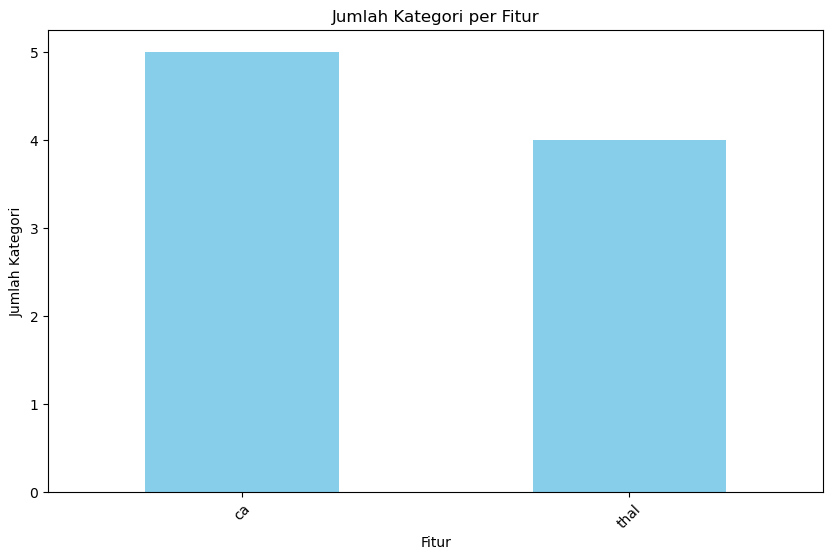

In [30]:
plt.figure(figsize=(10, 6))
CHD_data[categorical_features].nunique().plot(kind='bar', color='skyblue')
plt.title('Jumlah Kategori per Fitur')
plt.ylabel('Jumlah Kategori')
plt.xlabel('Fitur')
plt.xticks(rotation=45)
plt.show()

In [31]:
print('Data Unik pada ca: number of major vessels dan thal: results of nuclear stress test')
print('==='*5)
for feature in categorical_features:
    value = CHD_data[feature].value_counts()
    print(value)
    print('==='*5)


Data Unik pada ca: number of major vessels dan thal: results of nuclear stress test
ca
0    176
1     65
2     38
3     20
?      4
Name: count, dtype: int64
thal
3    166
7    117
6     18
?      2
Name: count, dtype: int64


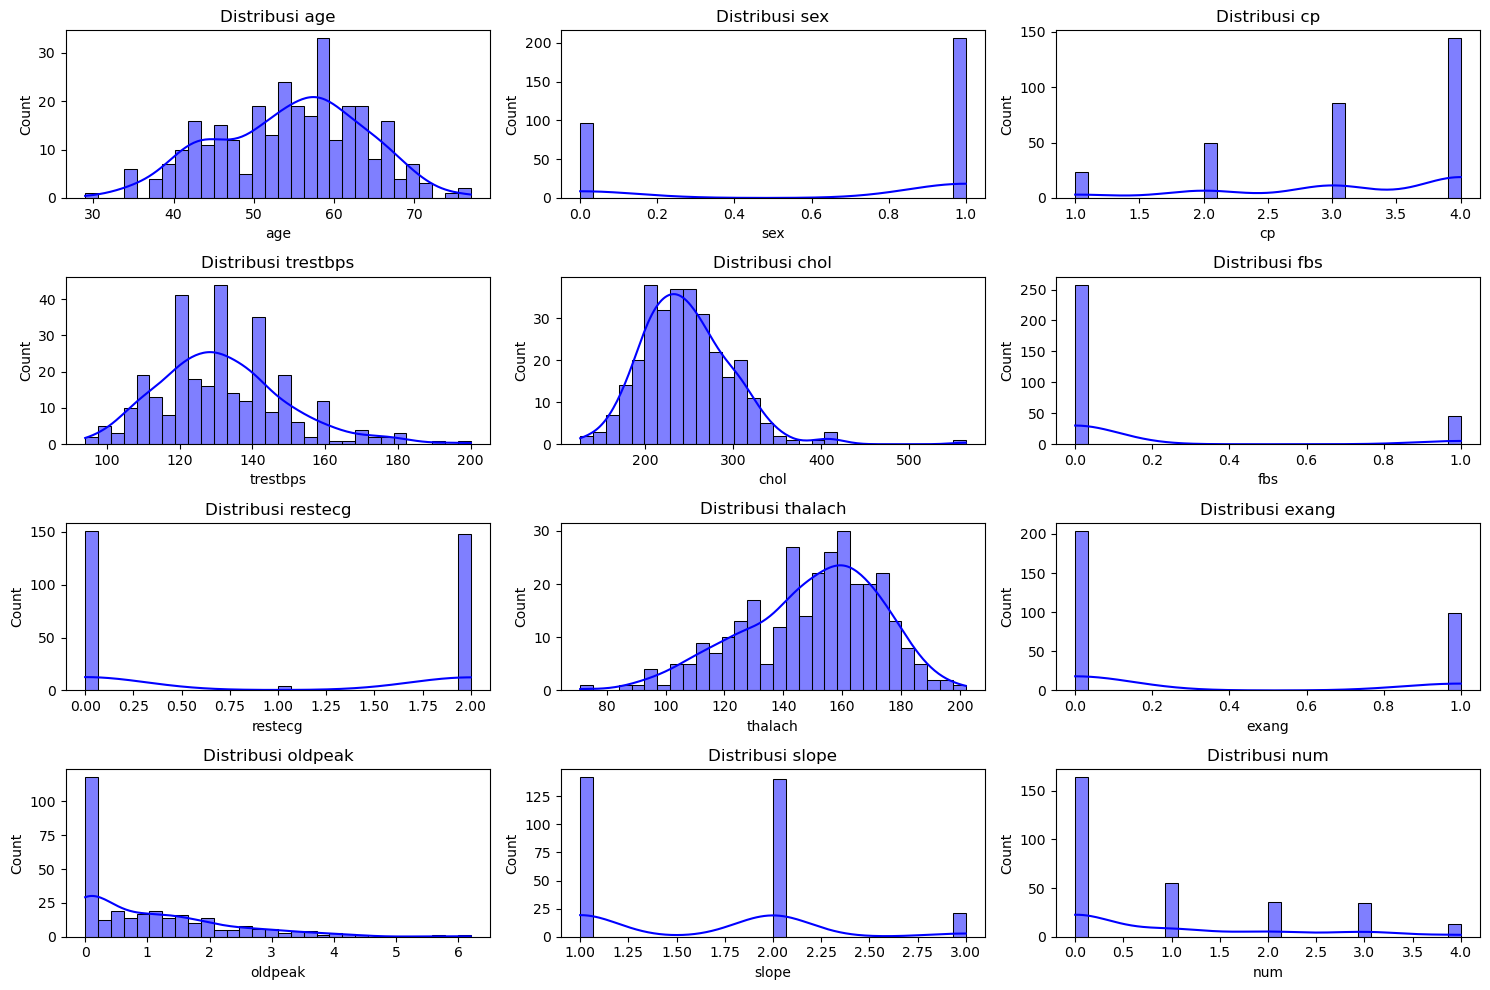

In [32]:
plt.figure(figsize=(15, 10))
for i, feature in enumerate(numerical_features, 1):
    plt.subplot(4, 3, i)
    sns.histplot(CHD_data[feature], kde=True, color='blue', bins=30)
    plt.title(f'Distribusi {feature}')
plt.tight_layout()
plt.show()

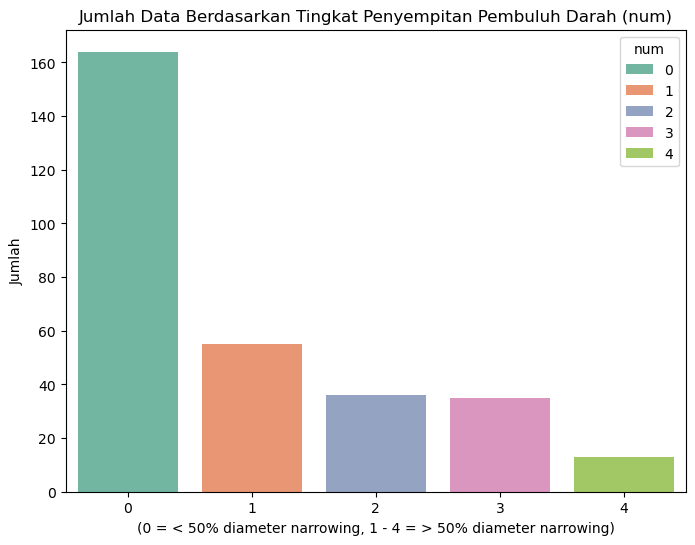

In [33]:
plt.figure(figsize=(8, 6))
sns.countplot(data=CHD_data, x='num', hue='num', palette='Set2')
plt.title('Jumlah Data Berdasarkan Tingkat Penyempitan Pembuluh Darah (num)')
plt.xlabel('(0 = < 50% diameter narrowing, 1 - 4 = > 50% diameter narrowing)')
plt.ylabel('Jumlah')
plt.show()

**Analisis :**
Berdasarkan deskripsi dari dataset nilai 1-4 memiliki lebih dari 50% penyempitan diameter. Oleh karena itu, nilai akan disederhanakan menjadi 1.

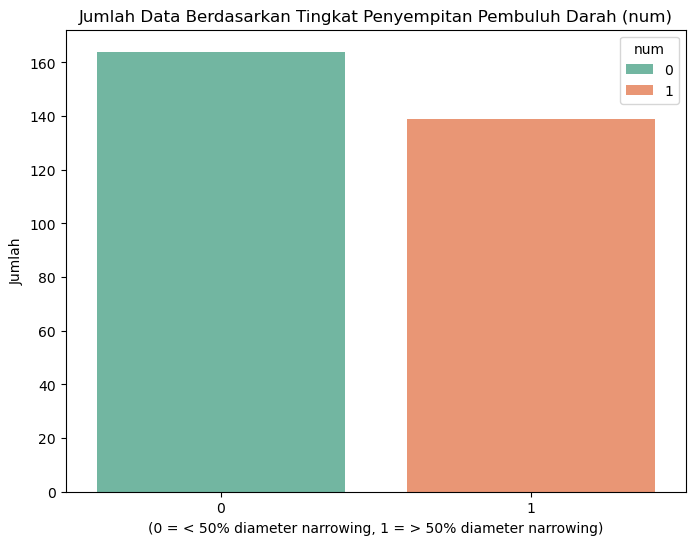

In [34]:
CHD_data['num'] = CHD_data['num'].apply(lambda x: 1 if x > 0 else 0)

plt.figure(figsize=(8, 6))
sns.countplot(data=CHD_data, x='num', hue='num', palette='Set2')
plt.title('Jumlah Data Berdasarkan Tingkat Penyempitan Pembuluh Darah (num)')
plt.xlabel('(0 = < 50% diameter narrowing, 1 = > 50% diameter narrowing)')
plt.ylabel('Jumlah')
plt.show()

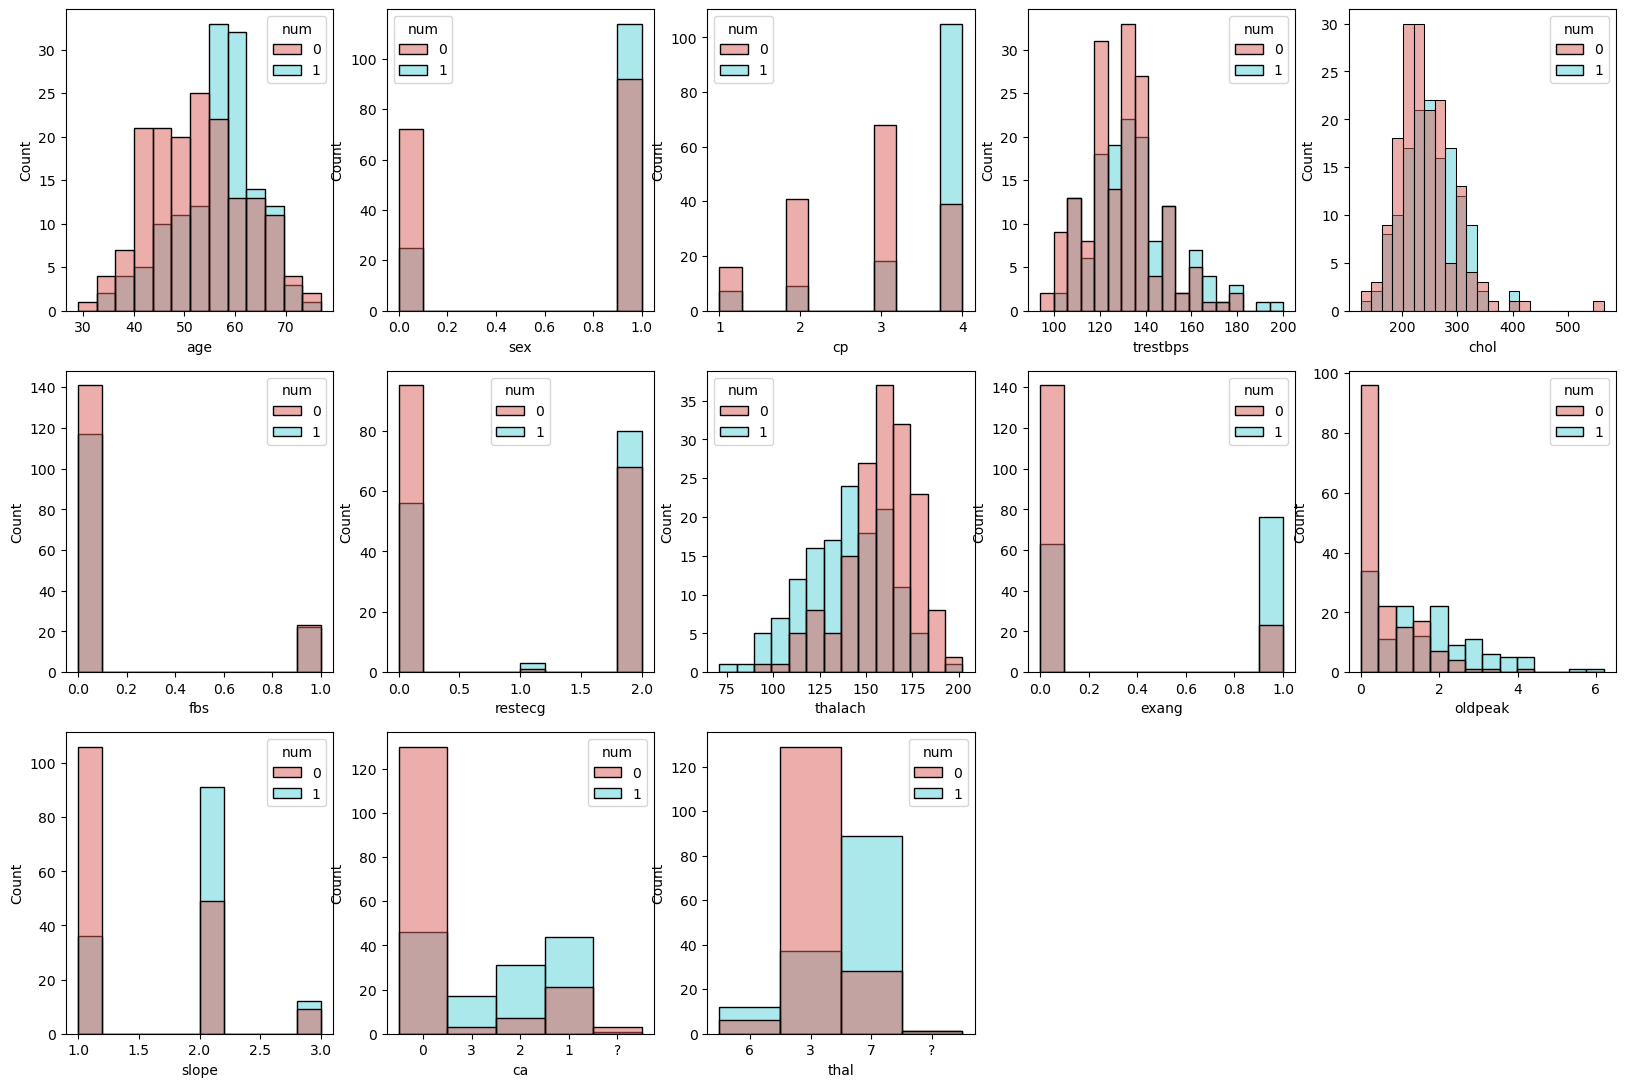

In [35]:
plt.figure(figsize = (20, 18))
for i, col in enumerate(CHD_data.drop('num', axis = 1).columns):
    plt.subplot(4, 5, i+1)
    sns.histplot(x = col, hue = 'num', data = CHD_data, palette='hls')
plt.show()

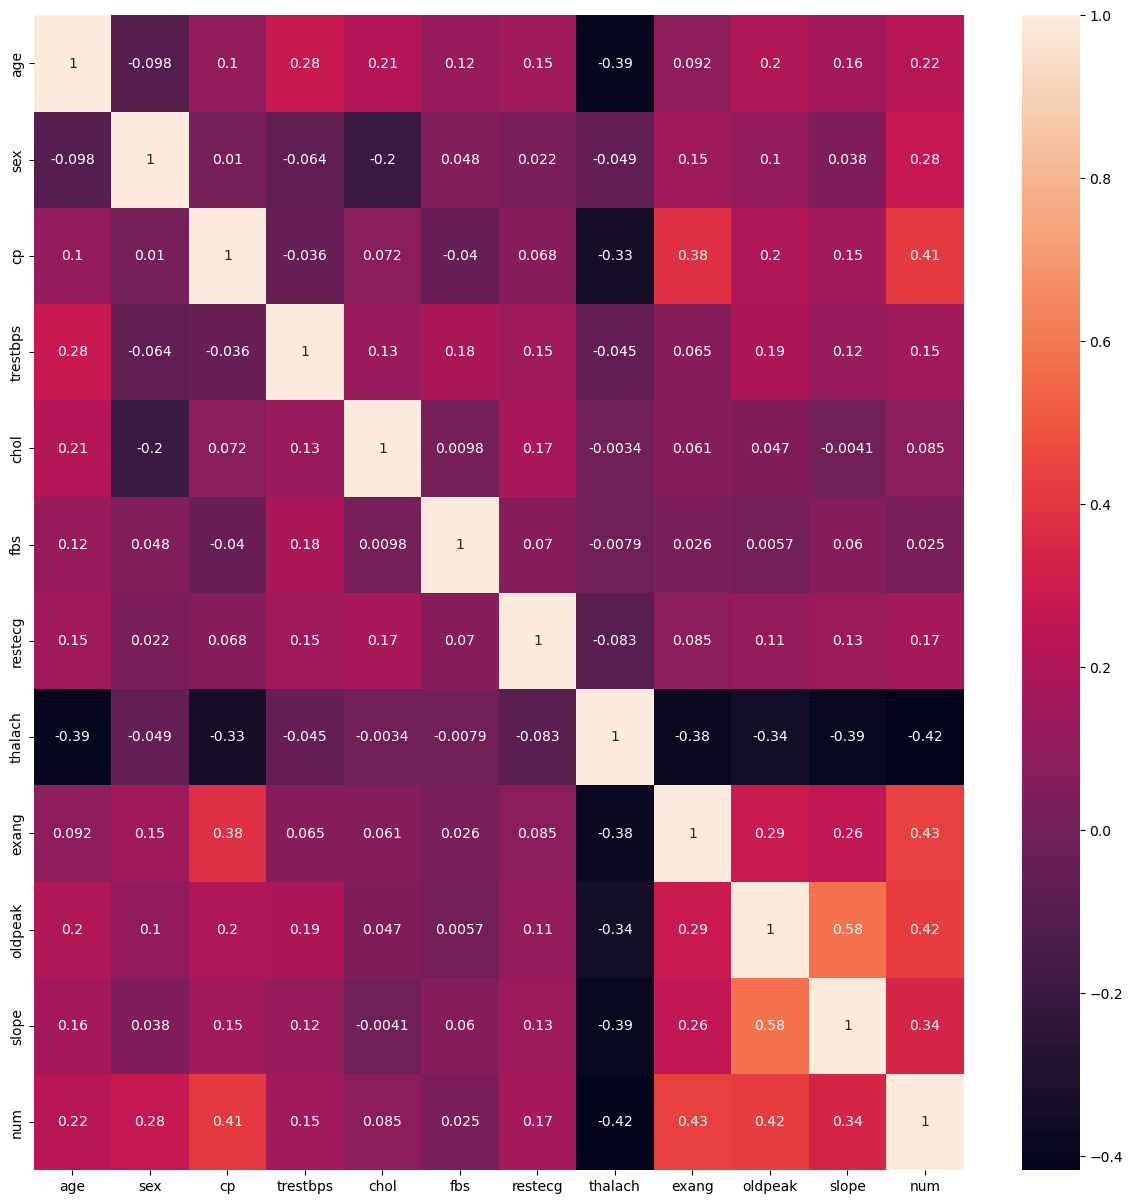

In [36]:
# Menampilkan korelasi antar fitur pada dataset

plt.figure(figsize=(15,15))
sns.heatmap(CHD_data.select_dtypes(include='number').corr(), annot=True)
plt.show()

In [37]:
CHD_data = CHD_data.drop(columns=['chol', 'fbs'])

#### Encode Data
Pada bagian ini kami melakukan pemetaan data kategorikal menjadi data numerik dengan fungsi LabelEncoder yang disediakan oleh pustaka scikit-learn

In [38]:
before_encode = CHD_data.copy()

lb = LabelEncoder()
for i in categorical_features:
    CHD_data[i] = lb.fit_transform(CHD_data[i])

In [39]:
CHD_data.head()

,age,sex,cp,trestbps,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,2,150,0,2.3,3,0,1,0
1,67,1,4,160,2,108,1,1.5,2,3,0,1
2,67,1,4,120,2,129,1,2.6,2,2,2,1
3,37,1,3,130,0,187,0,3.5,3,0,0,0
4,41,0,2,130,2,172,0,1.4,1,0,0,0


In [40]:
# Menampilkan data sesudah dan sebelum di encode
for feature in categorical_features:
    print(f'--{feature}--')
    print(before_encode[feature].unique())
    print(CHD_data[feature].unique())
    print('==='*8)

--ca--
['0' '3' '2' '1' '?']
[0 3 2 1 4]
--thal--
['6' '3' '7' '?']
[1 0 2 3]


### **Modelling**

#### Partitioning Dataset in Training and Test Sets
Pada tahapan ini kami melakukan pembagian dataset menjadi data training dan data testing dengan fungsi train_test_split yang disediakan pustaka scikit-learn. Selain itu, kami juga mengimplementasikan teknik over-sampling, yaitu teknik untuk menyeimbangkan distribusi kelas/fitur dengan menambahkan jumlah instansi atau data yang terlalu sedikit.

In [41]:
# melakukan pembagian dataset

X = CHD_data.drop('num', axis = 1)
y = CHD_data['num']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

#### Tuning Hyperparameter Random Forest dengan PSO
Pada model ini menggunakan Particle Swarm Optimization (PSO) untuk mencari parameter terbaik pada Random Forest

In [114]:
# Parameter PSO
n_particles = 40
max_iter = 100
dim = 4  # n_estimators, max_depth, min_samples_split, min_samples_leaf
w_max = 0.9
w_min = 0.4
c1 = 2.0 
c2 = 2.0 
bounds = [(10, 200), (1, 20), (2, 20), (1, 10)]  # Batas untuk hyperparameter

# Inisialisasi
particles = np.random.uniform(low=[b[0] for b in bounds], high=[b[1] for b in bounds], size=(n_particles, dim))
velocities = np.random.uniform(-1, 1, (n_particles, dim))
p_best = particles.copy()
g_best = particles[np.random.choice(n_particles)]

# Fungsi fitness
def fitness_function(params):
    params = np.round(params).astype(int)
    model = RandomForestClassifier(
        n_estimators=params[0],
        max_depth=params[1],
        min_samples_split=params[2],
        min_samples_leaf=params[3]
    )
    score = cross_val_score(model, X, y, cv=5, n_jobs=-1).mean()
    return score

# PSO loop
for iteration in range(max_iter):
    w = w_max - ((w_max - w_min) * iteration / max_iter)
    for i in range(n_particles):
        # Evaluasi fitness
        fitness = fitness_function(particles[i])
        if fitness > fitness_function(p_best[i]):
            p_best[i] = particles[i]
        if fitness > fitness_function(g_best):
            g_best = particles[i]

        # Update kecepatan dan posisi
        r1, r2 = np.random.rand(2)
        velocities[i] = (w * velocities[i] +
                         c1 * r1 * (p_best[i] - particles[i]) +
                         c2 * r2 * (g_best - particles[i]))
        particles[i] = np.clip(particles[i] + velocities[i], [b[0] for b in bounds], [b[1] for b in bounds])

# Model terbaik
best_params = np.round(g_best).astype(int)
print("Best Parameters:", best_params)


Best Parameters: [200   1  20   1]


#### Training Model
Pada bagian ini kami melatih model dengan data training yang sudah disediakan dan memasukkan parameter yang sudah ditentukan sebelumnya pada fungsi.

In [42]:
# Melakukan training model

RF_without_tuning = RandomForestClassifier()

# Trial 1: n_particles = 10
RF_with_tuning_1 = RandomForestClassifier(n_estimators=200, max_depth=1, min_samples_split=2, min_samples_leaf=1)

# Trial 2: n_particles = 15
RF_with_tuning_2 = RandomForestClassifier(n_estimators=200, max_depth=1 , min_samples_split=20 , min_samples_leaf=1)

# Trial 3: n_particles = 20
RF_with_tuning_3 = RandomForestClassifier(n_estimators=200, max_depth=1 , min_samples_split=20 , min_samples_leaf=1)

# Trial 4: n_particles = 30
RF_with_tuning_4 = RandomForestClassifier(n_estimators=200, max_depth=1 , min_samples_split=2 , min_samples_leaf=10)

# Trial 5: n_particles = 40
RF_with_tuning_5 = RandomForestClassifier(n_estimators=200, max_depth=1 , min_samples_split=20 , min_samples_leaf=1)


RF_without_tuning.fit(X_train, y_train)
RF_with_tuning_1.fit(X_train, y_train)
RF_with_tuning_2.fit(X_train, y_train)
RF_with_tuning_3.fit(X_train, y_train)
RF_with_tuning_4.fit(X_train, y_train)
RF_with_tuning_5.fit(X_train, y_train)

RandomForestClassifier(max_depth=1, min_samples_split=20, n_estimators=200)

#### Training Result

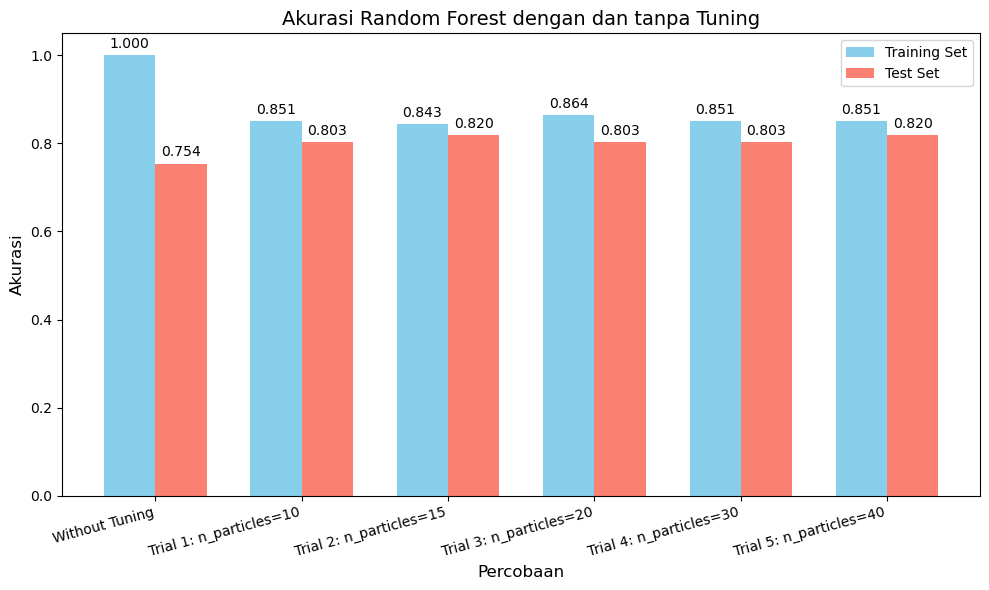

In [43]:
# Akurasi training dan test dari berbagai percobaan
training_accuracies = [
    RF_without_tuning.score(X_train, y_train),
    RF_with_tuning_1.score(X_train, y_train),
    RF_with_tuning_2.score(X_train, y_train),
    RF_with_tuning_3.score(X_train, y_train),
    RF_with_tuning_4.score(X_train, y_train),
    RF_with_tuning_5.score(X_train, y_train),
]

test_accuracies = [
    RF_without_tuning.score(X_test, y_test),
    RF_with_tuning_1.score(X_test, y_test),
    RF_with_tuning_2.score(X_test, y_test),
    RF_with_tuning_3.score(X_test, y_test),
    RF_with_tuning_4.score(X_test, y_test),
    RF_with_tuning_5.score(X_test, y_test),
]

# Labels untuk setiap percobaan
labels = [
    "Without Tuning",
    "Trial 1: n_particles=10",
    "Trial 2: n_particles=15",
    "Trial 3: n_particles=20",
    "Trial 4: n_particles=30",
    "Trial 5: n_particles=40",
]

# Index untuk bar plot
x = np.arange(len(labels))

# Lebar bar
width = 0.35

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))

# Bar plot untuk training dan test accuracies
bars1 = ax.bar(x - width/2, training_accuracies, width, label="Training Set", color="skyblue")
bars2 = ax.bar(x + width/2, test_accuracies, width, label="Test Set", color="salmon")

# Menambahkan label dan judul
ax.set_xlabel("Percobaan", fontsize=12)
ax.set_ylabel("Akurasi", fontsize=12)
ax.set_title("Akurasi Random Forest dengan dan tanpa Tuning", fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15, ha="right")
ax.legend()

# Menampilkan nilai akurasi di atas setiap bar
for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

plt.tight_layout()
plt.show()


In [44]:
models = {
           'RF_without_tuning': RF_without_tuning,
           'Trial 1: n_particles=10': RF_with_tuning_1,
           'Trial 2: n_particles=15': RF_with_tuning_2,
           'Trial 3: n_particles=20': RF_with_tuning_3,
           'Trial 4: n_particles=30': RF_with_tuning_4,
           'Trial 5: n_particles=40': RF_with_tuning_5
         }

results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy
    
    # Confusion Matrix
    print("Prediksi :", y_pred[:3])
    print("Label Sebenarnya :", y_test.values[:3])
    print("***"*20)
    print("---"*5 + " Model " + name + " " +"---"*5)
    print(classification_report(y_test, y_pred))





Prediksi : [0 1 1]
Label Sebenarnya : [0 0 1]
************************************************************
--------------- Model RF_without_tuning ---------------
              precision    recall  f1-score   support

           0       0.75      0.86      0.80        35
           1       0.76      0.62      0.68        26

    accuracy                           0.75        61
   macro avg       0.76      0.74      0.74        61
weighted avg       0.76      0.75      0.75        61

Prediksi : [0 0 1]
Label Sebenarnya : [0 0 1]
************************************************************
--------------- Model Trial 1: n_particles=10 ---------------
              precision    recall  f1-score   support

           0       0.77      0.94      0.85        35
           1       0.89      0.62      0.73        26

    accuracy                           0.80        61
   macro avg       0.83      0.78      0.79        61
weighted avg       0.82      0.80      0.80        61

Prediksi : [0 

#### Testing Model
Pada tahapan ini kami melakukan pengetesan pada model prediksi stroke yang sudah dilatih

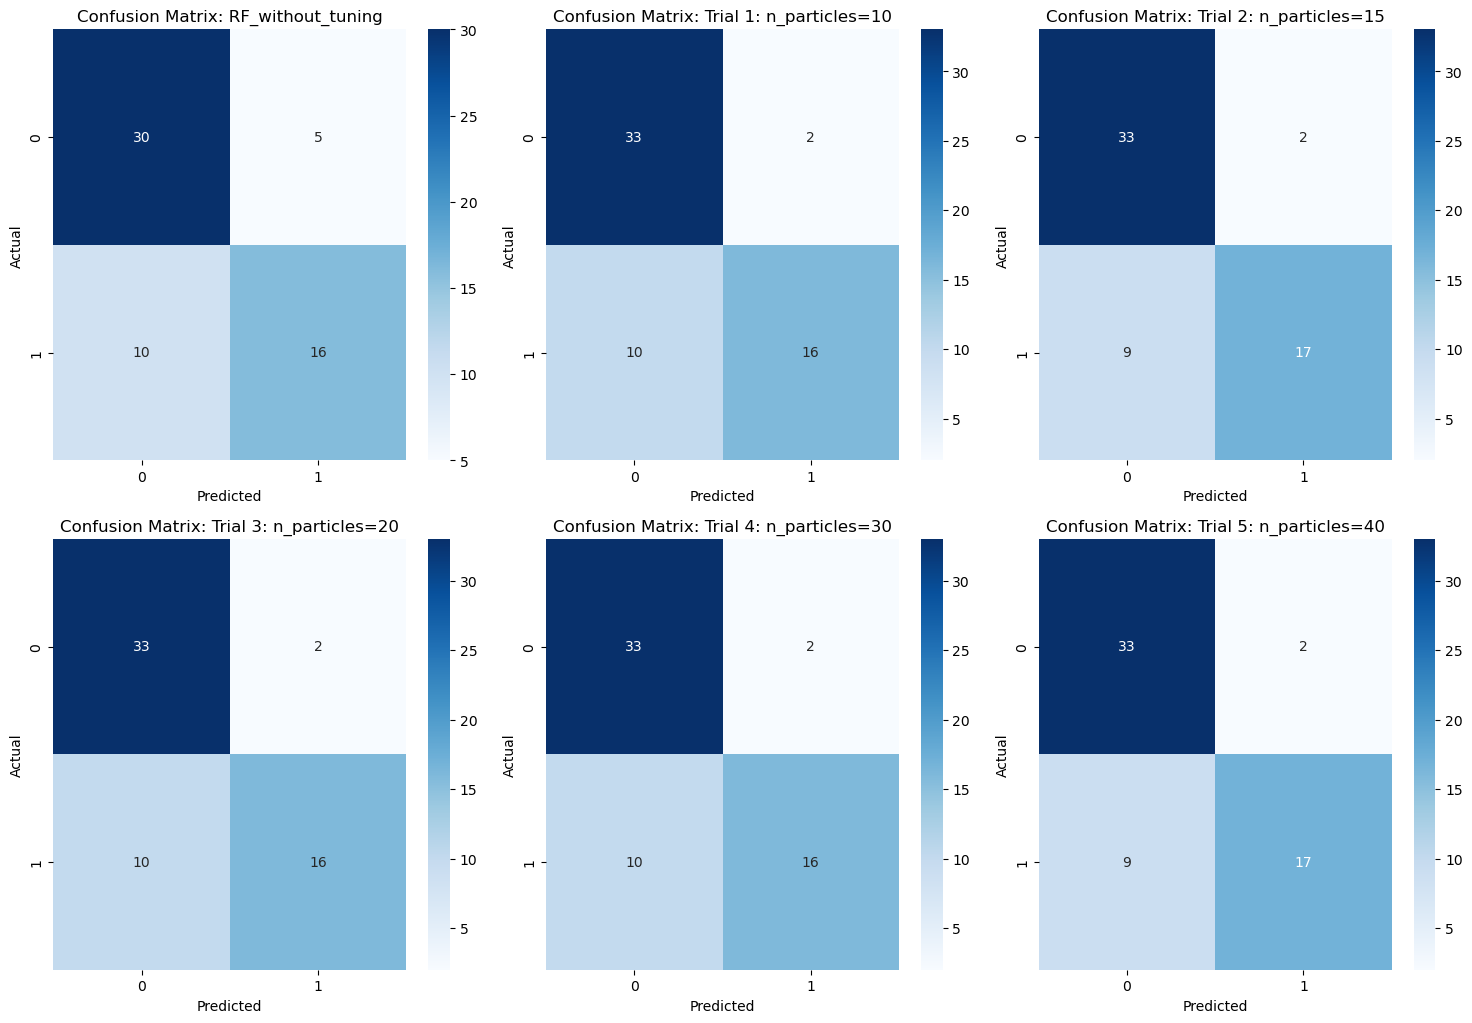

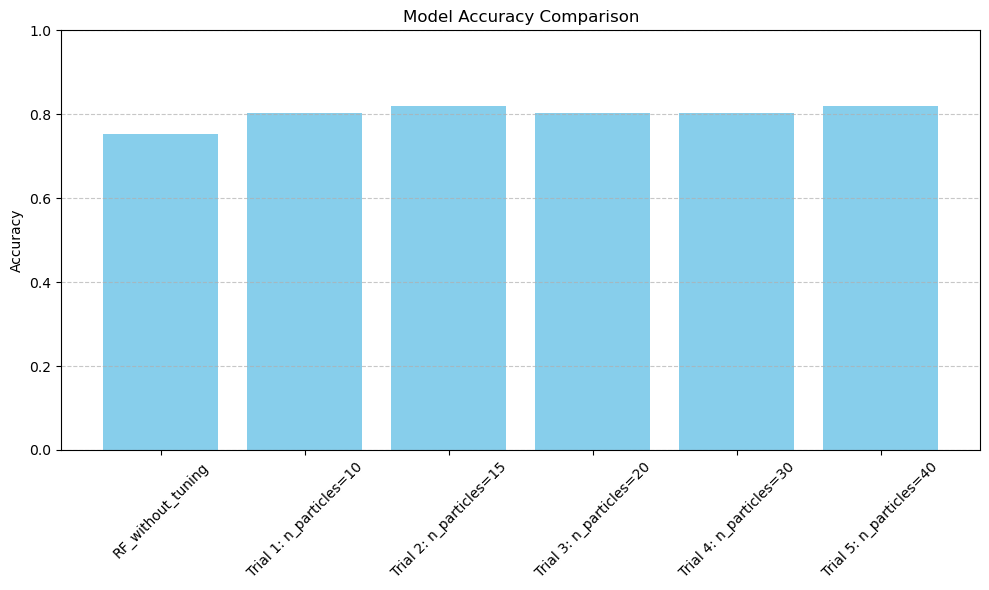

In [46]:
results = {}

# Ukuran figure utama untuk heatmap
plt.figure(figsize=(15, 15))

# Iterasi melalui model
for i, (name, model) in enumerate(models.items()):  # Perbaikan unpacking
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy  # Menyimpan akurasi dalam dictionary
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.subplot(3, 3, i + 1)  # Menyesuaikan subplot berdasarkan indeks
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                xticklabels=['0', '1'], yticklabels=['0', '1'])
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')

# Tampilkan heatmaps
plt.tight_layout()
plt.show()

# Membuat Bar Chart untuk Akurasi
plt.figure(figsize=(10, 6))
plt.bar(results.keys(), results.values(), color='skyblue')
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [47]:
!jupyter nbconvert --to html "./UAS2024_IF541_G_Kelompok_9.ipynb" --output-dir="./HTML Files"

[NbConvertApp] Converting notebook ./UAS2024_IF541_G_Kelompok_9.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 9 image(s).
[NbConvertApp] Writing 1086521 bytes to HTML Files\UAS2024_IF541_G_Kelompok_9.html


### **Next step**:
convert the generated html file to PDF using the online tool: https://www.sejda.com/html-to-pdf
* choose the following settings:
    * Page size: One long page
    * Page Orientation: auto
    * Use print stylesheet
* Submit your ipython notebook and PDF files

Markdown basics https://markdown-guide.readthedocs.io/en/latest/basics.html#